### The Study

The aim of this study is predict which channel customers use when purchasing groceries, milk, fresh produce and frozen goods. 

The file used for this analysis is the Wholesale Customer Data. 

### The Libraries

In [1]:
import pandas as pd
import numpy as np
import missingno 
import fuzzywuzzy
import seaborn as sns 
from sklearn import metrics
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

### The First Five Rows

In [2]:
df = pd.read_csv('Wholesale_Customers_Data.csv')
df.head()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


### Data Summary

In [3]:
df.describe()

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


### Looking for missing values 

In [4]:
df.isnull().sum()

Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

There are no missing values in the dataset. 

### The dtypes

The dtypes function will enable me to see what values are contained in each column. This will help me determine which columns have object values and look for duplicated values in those columns. 

In [5]:
df.dtypes

Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object

All the values contained in the different columns are integer values. There is a need to look for duplicated values. 

### Training and testing the data

In [6]:
feature_cols = ['Fresh','Milk','Grocery','Frozen']
x = df[feature_cols]
y = df['Channel']

#split the data into training and test set:
x_train, x_test, y_train, y_test = train_test_split(x,y, test_size=0.20, random_state=0, shuffle=True)
print("Training data:", x_train.shape, y_train.shape)
print("Test data:", x_test.shape,y_test.shape)

Training data: (352, 4) (352,)
Test data: (88, 4) (88,)


### The Logistic Regression

In [7]:
logreg = LogisticRegression()

#fit the model with the data
logreg.fit(x_train, y_train)

#prediction
y_pred = logreg.predict(x_test)
y_pred

C:\Users\nicolway\AppData\Local\Programs\Python\Python37\lib\site-packages\sklearn\linear_model\logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)


array([2, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 1, 1, 1, 1, 2, 2, 1, 1, 1, 2,
       1, 1, 1, 1, 2, 1, 2, 1, 1, 2, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 2,
       1, 2, 1, 1, 1, 1, 1, 1, 2, 2, 2, 1, 1, 1, 1, 1, 1, 2, 1, 2, 2, 1,
       2, 1, 2, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 2, 1, 2, 1],
      dtype=int64)

### Model Evaluations

### Confusion Metrics

In [8]:
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[52,  4],
       [ 6, 26]], dtype=int64)

### The Heat Map

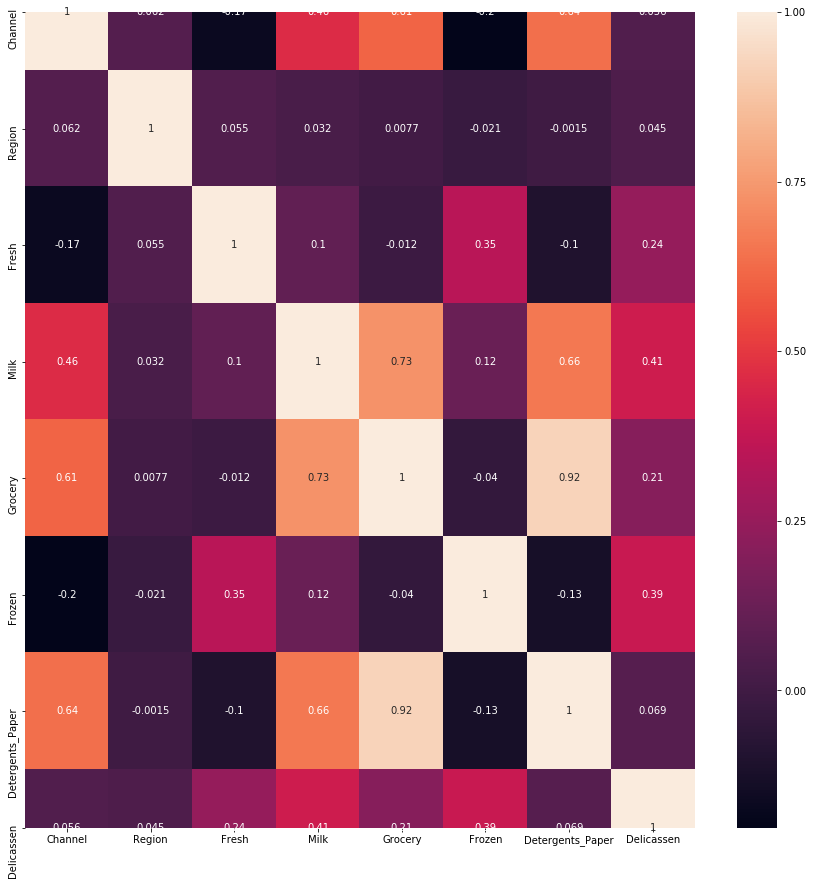

In [9]:
plt.figure(figsize = (15,15))
sns.heatmap(df.corr(), annot = True)

### Visualizing the confusion matrix using Heatmap

Text(0.5, 257.44, 'Predicted Label')

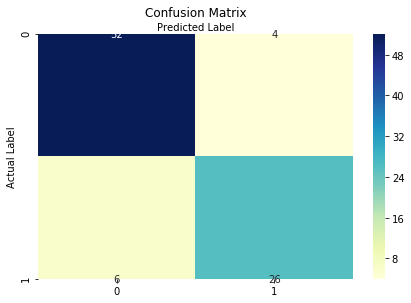

In [12]:
class_names =[1,2]
fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

#Creating the Map
sns.heatmap(pd.DataFrame(cnf_matrix), annot = True, cmap = "YlGnBu", fmt = 'g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion Matrix', y = 1.1)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')

### Confusion matrix evaluations

In [13]:
print("Accuracy:", metrics.accuracy_score(y_test,y_pred))
print("Precision:", metrics.precision_score(y_test,y_pred))
print("Recall:", metrics.recall_score(y_test,y_pred))

Accuracy: 0.8863636363636364
Precision: 0.896551724137931
Recall: 0.9285714285714286
